In [56]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [57]:
df = pd.read_csv('mpg.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   name          398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [80]:
X = df[['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin']]
y = df['mpg']
df = df.drop(df[df['horsepower'] == '?'].index)

In [81]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [83]:
model = LinearRegression()

In [84]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [77]:
# Ввод признаков
cylinders = float(input("Cylinders: "))
displacement = float(input("Displacement (in cubic inches): "))
horsepower = float(input("Horsepower: "))
weight = float(input("Weight (in lbs): "))
acceleration = float(input("Weight (in lbs): "))
model_year = float(input("Weight (in lbs): "))
origin = float(input("Weight (in lbs): "))
# Создание DataFrame в нужном формате
inputed_data = pd.DataFrame(
    data={
        'cylinders': cylinders,
        'displacement': displacement,
        'horsepower': horsepower,
        'weight': weight,
        'acceleration': acceleration,
        'model_year': model_year,
        'origin':origin
    },
    columns=X.columns,  # те же признаки, что и при обучении
    index=[0]
)

# Предсказание
print(f"Predicted MPG: {model.predict(inputed_data)[0]:.2f}")

Cylinders:  4
Displacement (in cubic inches):  119
Horsepower:  82
Weight (in lbs):  2720


Predicted MPG: 26.29


In [85]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [86]:
predictions = model.predict(X_test)

In [87]:
predictions

array([10.02764403, 20.27885779, 21.95209174, 32.207352  , 17.29888539,
       20.4896197 , 29.85237529, 19.75679483, 23.60473336, 25.95916973,
       30.56597136, 28.80013711, 29.74782913, 29.11442982, 29.05849715,
       23.96393524, 13.25342667, 24.33425506,  9.9337248 , 17.48758943,
       28.08715659, 24.06986501, 21.2458499 , 15.64595757, 30.22293968,
       31.25841549, 26.56866225, 10.21723013, 25.71637205, 11.42942876,
       34.97721953, 33.98293268, 26.6976695 , 28.98166348, 30.27733112,
       26.03537388, 28.78565523, 16.20086169,  5.19874085, 24.69804391,
       29.78245685, 22.70904008, 14.99682269, 15.5697844 , 11.87638248,
       26.18131985, 28.95926921, 16.55285328, 14.56329287, 20.90940433,
       26.10845244, 14.6741411 , 34.8233755 , 34.83418084, 24.10288506,
       22.16610472,  8.62715217, 24.83779203, 21.04679109, 29.84811785,
       28.70088549, 12.42752102, 27.19803978, 23.7909329 , 21.25788702,
       15.161599  , 14.96318914, 23.02110935, 24.89869914, 18.94

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [89]:
mean_absolute_error(y_test, predictions)

2.5784290583796277

<Axes: >

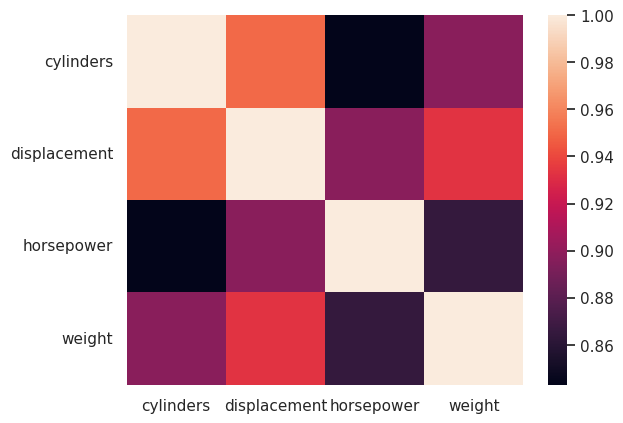

In [74]:
sns.heatmap(X.corr())

In [88]:
model.predict(X_test)

array([10.02764403, 20.27885779, 21.95209174, 32.207352  , 17.29888539,
       20.4896197 , 29.85237529, 19.75679483, 23.60473336, 25.95916973,
       30.56597136, 28.80013711, 29.74782913, 29.11442982, 29.05849715,
       23.96393524, 13.25342667, 24.33425506,  9.9337248 , 17.48758943,
       28.08715659, 24.06986501, 21.2458499 , 15.64595757, 30.22293968,
       31.25841549, 26.56866225, 10.21723013, 25.71637205, 11.42942876,
       34.97721953, 33.98293268, 26.6976695 , 28.98166348, 30.27733112,
       26.03537388, 28.78565523, 16.20086169,  5.19874085, 24.69804391,
       29.78245685, 22.70904008, 14.99682269, 15.5697844 , 11.87638248,
       26.18131985, 28.95926921, 16.55285328, 14.56329287, 20.90940433,
       26.10845244, 14.6741411 , 34.8233755 , 34.83418084, 24.10288506,
       22.16610472,  8.62715217, 24.83779203, 21.04679109, 29.84811785,
       28.70088549, 12.42752102, 27.19803978, 23.7909329 , 21.25788702,
       15.161599  , 14.96318914, 23.02110935, 24.89869914, 18.94

In [79]:
df.isnull().sum()


mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64